# Routex: Notebook 02, Data Preprocessing

**Project:** Routex, machine-learning-based vehicle fuel consumption prediction
**Author:** Member 2 (data preprocessing, EDA, first regression models)
**Input:** `data/raw/vehicles.csv` (not modified)
**Target:** `comb08`, combined city/highway fuel economy (MPG)

This notebook turns the raw dataset into clean, model-ready inputs. It:

1. inspects the columns and their data types,
2. investigates pure electric vehicles (whose `comb08` is MPGe, not MPG),
3. removes columns that would leak the answer to the model,
4. investigates unusual values, placeholders and outliers,
5. handles missing values and builds new features from messy columns,
6. separates numerical, binary and categorical features,
7. splits the data into training and test sets, and
8. builds a scikit-learn `Pipeline` / `ColumnTransformer` that is **fitted on the
   training data only**.

**No models are trained here.** That happens in the next notebook.

The reusable code lives in [`src/preprocessing.py`](../src/preprocessing.py), so the
modelling notebooks use exactly the same steps. This notebook explains and checks
each decision.

## 1. Setup

We fix a random seed so the train/test split is identical every time the notebook
is run. The seed and the test-set size are defined once in `src/preprocessing.py`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Make the project root importable whether the notebook runs from the root or notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src import preprocessing as prep

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR, prep.PROCESSED_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:  ", PROJECT_ROOT)
print("Python:        ", sys.version.split()[0])
print("pandas:        ", pd.__version__)
print("scikit-learn:  ", sklearn.__version__)
print("Random state:  ", prep.RANDOM_STATE)
print("Test size:     ", prep.TEST_SIZE)

Project root:   D:\ROUTEX
Python:         3.14.5
pandas:         3.1.1
scikit-learn:   1.9.1
Random state:   42
Test size:      0.2


## 2. Load and inspect the raw data

We load the raw CSV and record its size. The file on disk is only read, never changed.

In [2]:
raw = prep.load_raw_data()
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
print("\nColumns per data type:")
print(raw.dtypes.astype(str).value_counts())

Rows: 42,774   Columns: 83

Columns per data type:
float64    32
int64      27
str        23
bool        1
Name: count, dtype: int64


The table below profiles every column. As well as true missing values (`NaN`), it
counts **placeholder** values: this dataset often uses `-1` or `0` to mean "not
available", which a model would otherwise read as a real number.

In [3]:
numeric_cols = raw.select_dtypes("number").columns
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique": raw.nunique(),
    "missing_%": raw.isna().mean().mul(100).round(1),
    "minus1_%": (raw[numeric_cols] == -1).mean().mul(100).round(1),
    "zero_%": (raw[numeric_cols] == 0).mean().mul(100).round(1),
    "example": raw.iloc[0].astype(str).str[:30],
}).fillna({"minus1_%": 0, "zero_%": 0})
profile

,dtype,unique,missing_%,minus1_%,zero_%,example
UCity,float64,7927,0.0,0.0,0.1,23.3333
UCityA,float64,574,0.0,0.0,96.1,0.0
UHighway,float64,8164,0.0,0.0,0.1,35.0
UHighwayA,float64,631,0.0,0.0,96.1,0.0
VClass,str,34,0.0,0.0,0.0,Two Seaters
...,...,...,...,...,...,...
tCharger,str,1,81.9,0.0,0.0,NaN
trans_dscr,str,52,64.8,0.0,0.0,NaN
trany,str,40,0.0,0.0,0.0,Manual 5-spd
year,int64,38,0.0,0.0,0.0,1985


**What the profile shows:**

- Many columns are almost entirely `0`: `cityE`, `range`, `phevComb`, the `...A08`
  columns and others. They only apply to electric, plug-in hybrid or dual-fuel
  vehicles.
- `co2`, `feScore` and `ghgScore` use `-1` for "not measured" in about 75% of rows.
- Several text columns are mostly `NaN`, but the gap often has a **meaning**: an empty
  `tCharger` means "no turbo", an empty `atvType` means "conventional vehicle", and so on.
- `id` is unique for every row, and `model` has thousands of distinct values.

## 3. Pure electric vehicles

`comb08` is reported in **MPG** for petrol, diesel and gas vehicles. For pure electric
vehicles (EVs), however, it is reported in **MPGe** (miles per gallon *equivalent*), a
conversion based on 33.7 kWh of electricity = 1 gallon of petrol. The two are not the
same physical quantity.

Below we compare `comb08` across the different powertrain types.

In [4]:
ev_mask = prep.is_pure_electric(raw)
print(f"Pure EVs (fuelType1 == 'Electricity'): {ev_mask.sum()} rows "
      f"({ev_mask.mean() * 100:.2f}% of the data)")
print(f"Same rows flagged by atvType == 'EV':  {(ev_mask & raw['atvType'].eq('EV')).sum()}")

powertrain = raw["atvType"].fillna("Conventional")
by_powertrain = (
    raw.groupby(powertrain)["comb08"]
    .agg(count="count", mean="mean", median="median", min="min", max="max")
    .round(1)
    .sort_values("mean", ascending=False)
)
by_powertrain

Pure EVs (fuelType1 == 'Electricity'): 241 rows (0.56% of the data)
Same rows flagged by atvType == 'EV':  241


,count,mean,median,min,max
atvType,,,,,
EV,241,98.9,103.0,28,141
Hybrid,729,31.8,29.0,13,58
Plug-in Hybrid,196,30.8,28.0,17,54
Diesel,1148,24.0,23.0,14,41
Conventional,38912,20.1,20.0,7,48
CNG,50,18.3,14.0,9,31
FFV,1470,18.0,17.0,12,32
Bifuel (CNG),20,15.4,12.0,10,24
Bifuel (LPG),8,13.5,13.5,12,15


In [5]:
print("Engine data for pure EVs (an EV has no combustion engine):")
print(raw.loc[ev_mask, ["displ", "cylinders"]].describe().loc[["count", "mean"]])
print("\nPlug-in hybrids: comb08 vs combA08 (electric-mode rating) means")
phev = raw["atvType"].eq("Plug-in Hybrid")
print(raw.loc[phev, ["comb08", "combA08"]].mean().round(1))

Engine data for pure EVs (an EV has no combustion engine):
       displ  cylinders
count    1.0        0.0
mean     0.0        NaN

Plug-in hybrids: comb08 vs combA08 (electric-mode rating) means
comb08     30.8
combA08    74.4
dtype: float64


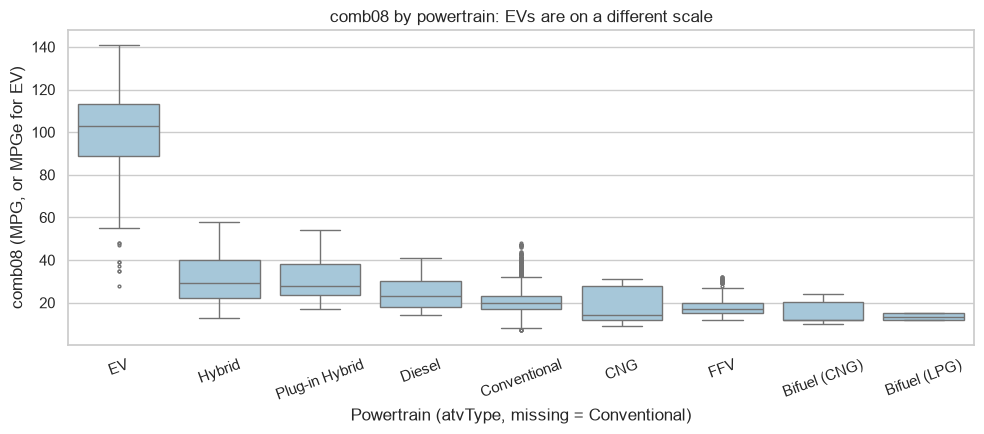

In [6]:
order = by_powertrain.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(x=powertrain, y=raw["comb08"], order=order, ax=ax, color="#9ecae1", fliersize=2)
ax.set_xlabel("Powertrain (atvType, missing = Conventional)")
ax.set_ylabel("comb08 (MPG, or MPGe for EV)")
ax.set_title("comb08 by powertrain: EVs are on a different scale")
plt.xticks(rotation=20)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_comb08_by_powertrain.png", dpi=120)
plt.show()

### Decision: exclude pure EVs (241 rows, 0.56%)

**Reasons:**

1. **Different unit.** EV `comb08` is MPGe, with a median around 100. Conventional
   vehicles have a median of 20 MPG. Mixing the two puts two different targets in
   one column.
2. **Different physics.** The model's main inputs (engine displacement, cylinders,
   transmission) do not exist for EVs (`displ`/`cylinders` are missing). Their
   efficiency depends on battery and motor characteristics, which this dataset barely
   describes.
3. **They would dominate the errors.** With only 241 rows, EVs are too few to learn
   from properly, yet their values (up to 141) are 5 times the typical target. A few
   EV mistakes would dominate MSE/RMSE and hide how well the model does on the other
   99.4% of vehicles.
4. **Project scope.** Routex predicts *fuel* consumption. A battery EV burns no fuel.

**What we keep:**

- **Hybrids** (729 rows): `comb08` is real petrol MPG (13 to 58).
- **Plug-in hybrids** (196 rows): `comb08` is the **petrol-only** rating (17 to 54).
  The electric MPGe rating is stored separately in `combA08` (mean about 74), which we
  exclude as leakage. So PHEV `comb08` is on the same MPG scale as other vehicles.

**Consequence:** the models will only be valid for vehicles with a combustion engine.
This limitation must be stated in the report.

## 4. Target leakage

**Data leakage** means giving the model information that would not be available for a
new vehicle, or that already contains the answer. City MPG (`city08`), for example, is
measured in the same EPA test as `comb08` and is almost perfectly correlated with it.
A model using it would look excellent but be useless in practice.

The project brief names eight leakage columns. While inspecting the data we found
**more columns that are the same measurement in a different form**:

| Group | Examples | Why it leaks |
|---|---|---|
| Unrounded MPG | `comb08U`, `city08U`, `highway08U` | `comb08U` *is* the target before rounding |
| Emissions & scores | `co2`, `feScore`, `ghgScore` | calculated from fuel economy |
| Gas-guzzler tax | `guzzler` | the US tax is applied **because** MPG is below a threshold |
| Second-fuel economy | `combA08`, `cityA08`, `UCityA`, `fuelCostA08`, ... | the same test, run on E85 / electricity / CNG |
| Electric results | `combE`, `cityCD`, `phevComb`, `range`, ... | outcomes of the efficiency test |

We check the claim numerically: the correlation of each candidate column with `comb08`
on the non-EV data. Values near ±1 confirm the leak. Columns that are `0`/`-1` for most
rows give weaker overall correlations, but they leak the target exactly for the rows
where they *are* filled in.

In [7]:
non_ev = raw.loc[~ev_mask]
leak_corr = (
    non_ev[[c for c in prep.LEAKAGE_COLUMNS if c in numeric_cols]]
    .corrwith(non_ev["comb08"])
    .rename("corr_with_comb08")
    .round(3)
    .to_frame()
)
leak_corr["group"] = [
    next(k for k, (_, cols) in prep.DROPPED_COLUMNS.items() if c in cols) for c in leak_corr.index
]
leak_corr.sort_values("corr_with_comb08", key=abs, ascending=False)

,corr_with_comb08,group
city08,0.986,leakage_required
UCity,0.981,leakage_required
highway08,0.969,leakage_required
UHighway,0.968,leakage_required
co2TailpipeGpm,-0.919,leakage_required
barrels08,-0.905,leakage_required
youSaveSpend,0.837,leakage_required
fuelCost08,-0.835,leakage_required
city08U,0.479,leakage_additional
comb08U,0.463,leakage_additional


In [8]:
print("Mean comb08 by gas-guzzler flag (G/T/S = guzzler tax applies):")
print(non_ev.groupby(non_ev["guzzler"].fillna("none"))["comb08"].agg(["count", "mean"]).round(1))
print("\n'GUZZLER' also appears inside the engine description text:")
print(f"  rows with 'GUZZLER' in eng_dscr: {non_ev['eng_dscr'].str.contains('GUZZLER', na=False).sum():,}")

Mean comb08 by gas-guzzler flag (G/T/S = guzzler tax applies):
         count  mean
guzzler             
G         1536  14.7
S           15  15.2
T          964  13.8
none     40018  20.7

'GUZZLER' also appears inside the engine description text:
  rows with 'GUZZLER' in eng_dscr: 979


**Decision:** drop all leakage columns (`prep.LEAKAGE_COLUMNS`, listed in full in
Section 8). The `guzzler` flag is dropped, and the `GUZZLER` tag is also **removed from
the engine-description text** (`eng_dscr`). Otherwise the same information would leak
in through the text. The rest of `eng_dscr` (e.g. `FFS`, `SIDI`, `TURBO`) describes the
engine and is kept.

## 5. Unusual values and outliers

### 5.1 Placeholder values

In [9]:
vol_cols = ["pv2", "pv4", "hpv", "lv2", "lv4", "hlv"]
print("Share of rows where interior-volume columns are 0 ('not reported'):")
print((non_ev[vol_cols] == 0).mean().mul(100).round(1).astype(str) + " %")
any_volume = (non_ev[["pv2", "pv4", "hpv"]] > 0).any(axis=1)
print(f"\nRows with at least one passenger volume reported: {any_volume.mean() * 100:.1f}%")

Share of rows where interior-volume columns are 0 ('not reported'):
pv2    83.8 %
pv4    64.8 %
hpv    88.4 %
lv2    83.8 %
lv4    64.8 %
hlv    88.4 %
dtype: str

Rows with at least one passenger volume reported: 54.2%


Each vehicle has its passenger/luggage volume in **one** of three column pairs (2-door,
4-door or hatchback), and the others are `0`. A volume of 0 cubic feet is impossible, so
`0` means "not reported". If we left these zeros in, a linear model would treat them as
a tiny car.

**Decision:** combine each group into a single `passenger_volume` / `luggage_volume`
column and turn `0` into a real missing value (`NaN`). It is then imputed with the
training median, and an extra 0/1 "was missing" indicator is added so the model can
still tell the difference.

Placeholders in `co2`, `feScore` and `ghgScore` (`-1`) do not need handling because
those columns are dropped as leakage.

### 5.2 Outliers in the target

In [10]:
target = non_ev["comb08"]
q1, q3 = target.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (target < low) | (target > high)
print(f"Non-EV comb08: Q1={q1}, Q3={q3}, IQR bounds=[{low}, {high}]")
print(f"Outliers: {(target < low).sum()} low, {(target > high).sum():,} high "
      f"({is_outlier.mean() * 100:.1f}% of rows)")
print("\nHigh outliers by powertrain:")
print(non_ev.loc[target > high, "atvType"].fillna("Conventional").value_counts())

Non-EV comb08: Q1=17.0, Q3=23.0, IQR bounds=[8.0, 32.0]
Outliers: 5 low, 1,069 high (2.5% of rows)

High outliers by powertrain:
atvType
Conventional      520
Hybrid            295
Diesel            186
Plug-in Hybrid     68
Name: count, dtype: int64


In [11]:
cols = ["year", "make", "model", "atvType", "displ", "cylinders", "comb08"]
print("Highest comb08 (non-EV):")
display(non_ev.nlargest(5, "comb08")[cols])
print("Lowest comb08:")
display(non_ev.nsmallest(5, "comb08")[cols])

Highest comb08 (non-EV):


,year,make,model,atvType,displ,cylinders,comb08
31315,2017,Hyundai,Ioniq Blue,Hybrid,1.6,4.0,58
32569,2018,Hyundai,Ioniq Blue,Hybrid,1.6,4.0,58
33590,2019,Hyundai,Ioniq Blue,Hybrid,1.6,4.0,58
35470,2020,Hyundai,Ioniq Blue,Hybrid,1.6,4.0,58
29854,2016,Toyota,Prius Eco,Hybrid,1.8,4.0,56


Lowest comb08:


,year,make,model,atvType,displ,cylinders,comb08
7901,1986,Lamborghini,Countach,NaN,5.2,12.0,7
21060,1987,Lamborghini,Countach,NaN,5.2,12.0,7
34552,1988,Lamborghini,Countach,NaN,5.2,12.0,7
37517,1989,Lamborghini,Countach,NaN,5.2,12.0,7
38791,1990,Lamborghini,Countach,NaN,5.2,12.0,7


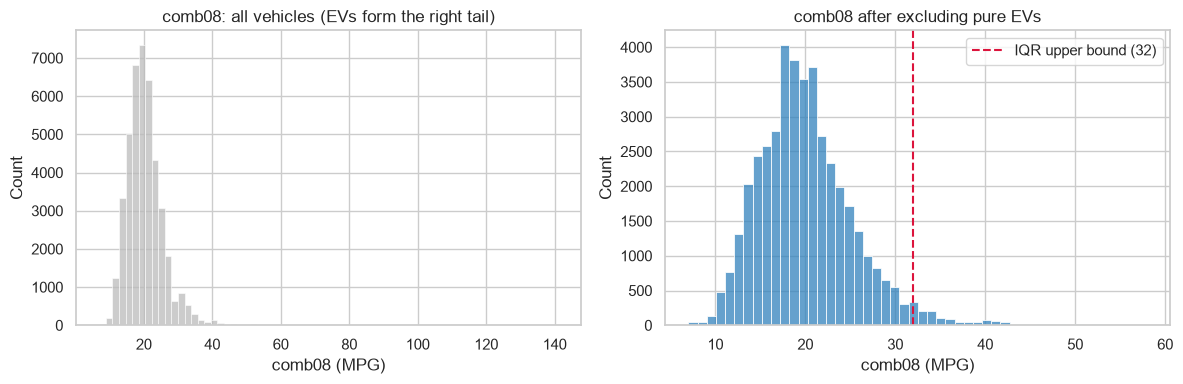

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(raw["comb08"], bins=70, ax=axes[0], color="#bbbbbb")
axes[0].set_title("comb08: all vehicles (EVs form the right tail)")
sns.histplot(target, bins=50, ax=axes[1], color="#3182bd")
axes[1].axvline(high, color="crimson", linestyle="--", label=f"IQR upper bound ({high:g})")
axes[1].set_title("comb08 after excluding pure EVs")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("comb08 (MPG)")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_comb08_distribution.png", dpi=120)
plt.show()

**Decision: keep the remaining outliers.** They are **genuine vehicles**, not errors:
the high values are hybrids (Hyundai Ioniq, Toyota Prius), small diesels and efficient
compacts, and the low values are supercars (Lamborghini Countach, Ferrari F50). These
are exactly the vehicles where fuel consumption matters most, and removing them would
make the model look better on paper while failing on real hybrids. The values are
physically plausible (7 to 58 MPG), there are no zero or negative values, and the
features (hybrid flag, displacement, cylinders) explain them.

### 5.3 Unusual values in the input features

In [13]:
print(non_ev[["year", "displ", "cylinders"]].describe().round(2))
print("\nRows with missing displ/cylinders:")
non_ev.loc[non_ev["displ"].isna() | non_ev["cylinders"].isna(),
           ["year", "make", "model", "displ", "cylinders"]]

           year     displ  cylinders
count  42533.00  42531.00   42530.00
mean    2002.18      3.29       5.71
std       11.49      1.36       1.76
min     1984.00      0.60       2.00
25%     1992.00      2.20       4.00
50%     2003.00      3.00       6.00
75%     2012.00      4.30       6.00
max     2021.00      8.40      16.00

Rows with missing displ/cylinders:


,year,make,model,displ,cylinders
21413,1985,Subaru,RX Turbo,NaN,NaN
21414,1985,Subaru,RX Turbo,NaN,NaN
21506,1986,Mazda,RX-7,1.3,NaN


Once EVs are removed, every engine has a displacement between 0.6 and 8.4 litres and 2
to 16 cylinders, all realistic. The few gaps are old 1985/86 Subaru and Mazda rotary
records. They are **imputed** (training median) rather than dropped.

In [14]:
print("Missing 'drive' by model year:")
print(non_ev.loc[non_ev["drive"].isna(), "year"].value_counts())

Missing 'drive' by model year:
year
1984    1178
Name: count, dtype: int64


All missing `drive` values come from model year 1984, when the field was not recorded.
They are filled with the category `"Missing"` inside the pipeline, so the model can
learn that pattern instead of us guessing a drive type.

### 5.4 Duplicate records

In [15]:
dups = non_ev.drop(columns="id").duplicated()
print(f"Exact duplicate rows (all columns):        {non_ev.duplicated().sum()}")
print(f"Duplicates ignoring only the 'id' column:  {dups.sum()}")

Exact duplicate rows (all columns):        0
Duplicates ignoring only the 'id' column:  40


**Decision:** remove these 40 records. They are the same vehicle stored twice under
different ids. A copy could end up in both the training and the test set, which would
make test scores optimistic. Vehicles that merely share the same *specifications*
(e.g. the same model in several years) are different records and are kept.

## 6. Feature engineering

Some raw columns hold useful information in an awkward format. Instead of dropping
them, we convert them into cleaner features (`prep.engineer_features`):

| New feature | Built from | How |
|---|---|---|
| `trans_type` | `trany` | first word: Automatic / Manual |
| `trans_speeds` | `trany` | number of gears, e.g. `Automatic (S6)` → 6 (missing for CVTs) |
| `is_cvt` | `trany` | 1 for continuously variable transmissions |
| `passenger_volume`, `luggage_volume` | `pv2/pv4/hpv`, `lv2/lv4/hlv` | combined, `0` → missing |
| `turbo`, `supercharger` | `tCharger`, `sCharger` | `T`/`S` → 1, empty → 0 |
| `eng_dscr` (cleaned) | `eng_dscr` | `GUZZLER` tag removed, empty → `"Not specified"` |

Missing values **with a known meaning** are filled with a label (fixed rules, nothing is
learned from the data):

- `atvType`: empty → `"Conventional"`
- `fuelType2`: empty → `"Single fuel"`
- `startStop`: empty → `"Not reported"` (the field was only recorded from about 2012)
- `trans_dscr`: empty → `"Not specified"` (no special transmission feature)

`trany` itself is kept as a categorical feature too, because its codes (e.g. `AM` =
automated manual, `S` = select-shift) carry more detail than the type and gear count.

In [16]:
engineered = prep.engineer_features(raw.loc[~ev_mask])
examples = engineered[["trany", "trans_type", "trans_speeds", "is_cvt"]].drop_duplicates("trany")
examples.sort_values(["is_cvt", "trany"]).head(12)

,trany,trans_type,trans_speeds,is_cvt
24738,Automatic (A1),Automatic,1.0,0
36017,Automatic (AM-S10),Automatic,10.0,0
23268,Automatic (AM-S6),Automatic,6.0,0
24484,Automatic (AM-S7),Automatic,7.0,0
27238,Automatic (AM-S8),Automatic,8.0,0
30153,Automatic (AM-S9),Automatic,9.0,0
17923,Automatic (AM5),Automatic,5.0,0
17998,Automatic (AM6),Automatic,6.0,0
18189,Automatic (AM7),Automatic,7.0,0
27835,Automatic (AM8),Automatic,8.0,0


In [17]:
print("Engine description before / after cleaning (examples containing GUZZLER):")
sample = raw.loc[raw["eng_dscr"].str.contains("GUZZLER", na=False), "eng_dscr"].drop_duplicates().head(5)
pd.DataFrame({"before": sample, "after": prep.clean_engine_description(sample)})

Engine description before / after cleaning (examples containing GUZZLER):


,before,after
1,(GUZZLER),Not specified
20,(GUZZLER) (FFS),(FFS)
99,(GUZZLER) (FFS) (MPFI),(FFS) (MPFI)
100,"(GUZZLER) (FFS,TRBO) (MPFI)","(FFS,TRBO) (MPFI)"
1935,(GUZZLER) (FFS) CA model,(FFS) CA model


## 7. Apply the cleaning rules

`prep.clean_dataset` performs Sections 3 to 6 in one call: it excludes pure EVs, removes
duplicate records, engineers the features above and keeps only the model inputs plus the
target. These are fixed, row-by-row rules that learn nothing from the data, so they are
safe to apply **before** the train/test split.

In [18]:
clean, clean_report = prep.clean_dataset(raw)
for key, value in clean_report.items():
    print(f"{key:<26} {value:,}")
print(f"\nColumns in cleaned data: {clean.shape[1]} ({len(prep.FEATURES)} features + target)")
clean.head()

rows_raw                   42,774
rows_removed_pure_ev       241
rows_removed_duplicates    40
rows_clean                 42,493
n_features                 22

Columns in cleaned data: 23 (22 features + target)


,year,displ,cylinders,trans_speeds,passenger_volume,luggage_volume,turbo,supercharger,is_cvt,phevBlended,make,VClass,drive,trany,trans_type,trans_dscr,fuelType,fuelType1,fuelType2,atvType,startStop,eng_dscr,comb08
0,1985,2.0,4.0,5.0,NaN,NaN,0,0,0,0,Alfa Romeo,Two Seaters,Rear-Wheel Drive,Manual 5-spd,Manual,Not specified,Regular,Regular Gasoline,Single fuel,Conventional,Not reported,(FFS),21
1,1985,4.9,12.0,5.0,NaN,NaN,0,0,0,0,Ferrari,Two Seaters,Rear-Wheel Drive,Manual 5-spd,Manual,Not specified,Regular,Regular Gasoline,Single fuel,Conventional,Not reported,Not specified,11
2,1985,2.2,4.0,5.0,77.0,19.0,0,0,0,0,Dodge,Subcompact Cars,Front-Wheel Drive,Manual 5-spd,Manual,SIL,Regular,Regular Gasoline,Single fuel,Conventional,Not reported,(FFS),27
3,1985,5.2,8.0,3.0,NaN,NaN,0,0,0,0,Dodge,Vans,Rear-Wheel Drive,Automatic 3-spd,Automatic,Not specified,Regular,Regular Gasoline,Single fuel,Conventional,Not reported,Not specified,11
4,1993,2.2,4.0,5.0,90.0,14.0,1,0,0,0,Subaru,Compact Cars,4-Wheel or All-Wheel Drive,Manual 5-spd,Manual,Not specified,Premium,Premium Gasoline,Single fuel,Conventional,Not reported,"(FFS,TRBO)",19


## 8. Every raw column is accounted for

To make sure no column was dropped by accident, we list all 83 raw columns with the
decision taken and the reason. The check fails loudly if any column has no decision.

In [19]:
accounting = prep.column_accounting(raw.columns)
assert (accounting["decision"] != "UNACCOUNTED").all(), "Some columns have no decision!"
assert set(prep.LEAKAGE_COLUMNS).isdisjoint(prep.FEATURES), "A leakage column is a feature!"
assert prep.ID_COLUMN not in prep.FEATURES, "The id column must not be a feature!"
print("Decisions:")
print(accounting["decision"].value_counts().to_string())
accounting.sort_values(["decision", "column"]).reset_index(drop=True)

Decisions:
decision
dropped: leakage_electric            18
kept                                 15
dropped: leakage_alternative_fuel    13
dropped: leakage_required             8
dropped: replaced_by_engineered       8
dropped: leakage_additional           7
dropped: sparse_or_redundant          6
dropped: identifier                   3
dropped: metadata                     3
dropped: constant                     1
target                                1


,column,decision,reason
0,charge120,dropped: constant,"Constant: the same value in every row, so it c..."
1,engId,dropped: identifier,Identifier: unique or near-unique codes that w...
2,id,dropped: identifier,Identifier: unique or near-unique codes that w...
3,model,dropped: identifier,Identifier: unique or near-unique codes that w...
4,city08U,dropped: leakage_additional,Target leakage (found during inspection): unro...
...,...,...,...
78,startStop,kept,Used as a model input.
79,trans_dscr,kept,Used as a model input.
80,trany,kept,Used as a model input.
81,year,kept,Used as a model input.


## 9. Feature types

| Type | Features | Preprocessing (learned on training data) |
|---|---|---|
| **Numerical** | `year`, `displ`, `cylinders`, `trans_speeds`, `passenger_volume`, `luggage_volume` | median imputation + missing indicator, then standard scaling |
| **Binary** | `turbo`, `supercharger`, `is_cvt`, `phevBlended` | passed through as 0/1 |
| **Categorical** | `make`, `VClass`, `drive`, `trany`, `trans_type`, `trans_dscr`, `fuelType`, `fuelType1`, `fuelType2`, `atvType`, `startStop`, `eng_dscr` | `"Missing"` imputation + one-hot encoding |

**Why these choices?**

- **Scaling** is needed for Linear Regression (and makes its coefficients comparable).
  It does no harm to tree-based models, so one preprocessor serves all three models.
- **One-hot encoding** because these categories have no natural order.
- **Rare categories** (seen fewer than 20 times in the training data) are grouped into
  one `infrequent` column. This keeps `make` (134 brands) and `eng_dscr` (500+ codes)
  usable without creating hundreds of near-empty columns or dropping them.
- **Unseen categories** in the test set (or in future data) are mapped to the
  infrequent group instead of causing an error.

In [20]:
feature_types = pd.DataFrame({
    "type": (["numerical"] * len(prep.NUMERIC_FEATURES) + ["binary"] * len(prep.BINARY_FEATURES)
             + ["categorical"] * len(prep.CATEGORICAL_FEATURES)),
    "dtype": clean[prep.FEATURES].dtypes.astype(str).values,
    "unique_values": clean[prep.FEATURES].nunique().values,
    "missing": clean[prep.FEATURES].isna().sum().values,
    "missing_%": clean[prep.FEATURES].isna().mean().mul(100).round(1).values,
}, index=prep.FEATURES)
feature_types

,type,dtype,unique_values,missing,missing_%
year,numerical,int64,38,0,0.0
displ,numerical,float64,65,2,0.0
cylinders,numerical,float64,9,3,0.0
trans_speeds,numerical,float64,9,1397,3.3
passenger_volume,numerical,float64,97,19460,45.8
luggage_volume,numerical,float64,53,19453,45.8
turbo,binary,int64,2,0,0.0
supercharger,binary,int64,2,0,0.0
is_cvt,binary,int64,2,0,0.0
phevBlended,binary,int64,2,0,0.0


## 10. Train/test split

We hold out **20%** of the data as a test set, with a fixed `random_state` so the split
is reproducible. The test set is only used for the final evaluation of the models.

In [21]:
X_train, X_test, y_train, y_test = prep.split_features_target(clean)
print(f"Training set: {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print("\nTarget distribution (should be similar in both sets):")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).round(2)

Training set: 33,994 rows x 22 features
Test set:     8,499 rows x 22 features

Target distribution (should be similar in both sets):


,train,test
count,33994.00,8499.00
mean,20.38,20.24
std,5.33,5.37
min,7.00,7.00
25%,17.00,17.00
50%,20.00,20.00
75%,23.00,23.00
max,58.00,58.00


## 11. Build the preprocessing pipeline and fit it on the training data only

The `ColumnTransformer` learns values from data: medians for imputation, means and
standard deviations for scaling, and the list of categories for one-hot encoding. If it
were fitted on all the data, test-set information would leak into training. So we:

1. **fit** it on `X_train` only, then
2. **transform** `X_test` with the values learned from the training set.

In the modelling notebook the preprocessor goes inside one `Pipeline` together with the
model (`Pipeline([("preprocess", ...), ("model", ...)])`), so this rule is also
followed automatically during cross-validation.

In [22]:
preprocessor = prep.build_preprocessor().set_output(transform="pandas")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

In [23]:
X_train_prepared = preprocessor.fit_transform(X_train)   # learn + apply (training only)
X_test_prepared = preprocessor.transform(X_test)         # apply only

print(f"Training matrix: {X_train_prepared.shape}")
print(f"Test matrix:     {X_test_prepared.shape}")
print(f"Missing values after preprocessing: train={X_train_prepared.isna().sum().sum()}, "
      f"test={X_test_prepared.isna().sum().sum()}")
print(f"Rows the preprocessor was fitted on: {preprocessor.n_features_in_} features, "
      f"{len(X_train):,} training rows")

Training matrix: (33994, 267)
Test matrix:     (8499, 267)
Missing values after preprocessing: train=0, test=0
Rows the preprocessor was fitted on: 22 features, 33,994 training rows


### 11.1 Checks that the fit used training data only

In [24]:
num_pipe = preprocessor.named_transformers_["num"]
scaler = num_pipe.named_steps["scale"]
imputer = num_pipe.named_steps["impute"]

# 1. The scaler saw exactly the training rows.
assert scaler.n_samples_seen_ == len(X_train)

# 2. The learned medians equal the TRAINING medians (not the full-data medians).
train_medians = X_train[prep.NUMERIC_FEATURES].median()
assert np.allclose(imputer.statistics_, train_medians.values)

# 3. Scaled training columns have mean ~0 / std ~1; test columns only approximately.
scaled_cols = [f"num__{c}" for c in prep.NUMERIC_FEATURES]
print("Mean of scaled numeric features:")
print(pd.DataFrame({
    "train_mean": X_train_prepared[scaled_cols].mean().round(3),
    "test_mean": X_test_prepared[scaled_cols].mean().round(3),
}))
print("\nLearned medians (training set):")
print(pd.Series(imputer.statistics_, index=prep.NUMERIC_FEATURES))
print("\nAll leakage checks passed.")

Mean of scaled numeric features:
                       train_mean  test_mean
num__year                    -0.0     -0.016
num__displ                   -0.0      0.010
num__cylinders                0.0      0.015
num__trans_speeds             0.0     -0.014
num__passenger_volume        -0.0      0.006
num__luggage_volume          -0.0     -0.011

Learned medians (training set):
year                2003.0
displ                  3.0
cylinders              6.0
trans_speeds           5.0
passenger_volume      91.0
luggage_volume        14.0
dtype: float64

All leakage checks passed.


### 11.2 The resulting feature columns

In [25]:
names = pd.Series(X_train_prepared.columns)
block = names.str.split("__").str[0].map({"num": "numerical (+ missing flags)", "bin": "binary", "cat": "one-hot categorical"})
print("Output columns per block:")
print(block.value_counts().to_string())

onehot = preprocessor.named_transformers_["cat"].named_steps["onehot"]
encoded_per_feature = pd.DataFrame({
    "categories_in_train": [len(c) for c in onehot.categories_],
    "grouped_as_infrequent": [0 if i is None else len(i) for i in onehot.infrequent_categories_],
}, index=prep.CATEGORICAL_FEATURES)
encoded_per_feature

Output columns per block:
one-hot categorical            252
numerical (+ missing flags)     11
binary                           4


,categories_in_train,grouped_as_infrequent
make,125,65
VClass,32,3
drive,8,0
trany,40,11
trans_type,3,1
trans_dscr,52,29
fuelType,13,3
fuelType1,5,0
fuelType2,5,2
atvType,8,2


## 12. Save the outputs

| Output | Location | In Git? |
|---|---|---|
| Cleaned training / test data (before encoding) | `data/processed/train.csv`, `test.csv` | No (ignored, rebuilt by this notebook) |
| Fitted preprocessor | `models/preprocessor.joblib` | No (ignored, rebuilt by this notebook) |
| Preprocessing summary (decisions, counts, feature lists) | `results/preprocessing_summary.json` | Yes |
| Figures | `reports/figures/02_*.png` | Yes |

The processed CSVs keep the readable, unencoded features plus `comb08`. The next
notebook should load them and fit `Pipeline(build_preprocessor(), model)` on the
training data. Re-running this notebook always produces identical files.

In [26]:
train_out = X_train.assign(**{prep.TARGET: y_train})
test_out = X_test.assign(**{prep.TARGET: y_test})
train_out.to_csv(prep.PROCESSED_DIR / "train.csv", index=False)
test_out.to_csv(prep.PROCESSED_DIR / "test.csv", index=False)
joblib.dump(preprocessor, MODELS_DIR / "preprocessor.joblib")

summary = {
    "source": "data/raw/vehicles.csv",
    "target": prep.TARGET,
    "random_state": prep.RANDOM_STATE,
    "test_size": prep.TEST_SIZE,
    "row_counts": {**clean_report, "train": len(X_train), "test": len(X_test)},
    "electric_vehicle_decision": (
        "Excluded pure EVs (fuelType1 == 'Electricity'): their comb08 is MPGe, not MPG. "
        "Hybrids and plug-in hybrids are kept (their comb08 is petrol MPG)."
    ),
    "outlier_decision": "Kept: genuine hybrids, diesels and supercars, not data errors.",
    "features": {
        "numerical": prep.NUMERIC_FEATURES,
        "binary": prep.BINARY_FEATURES,
        "categorical": prep.CATEGORICAL_FEATURES,
    },
    "n_columns_after_encoding": int(X_train_prepared.shape[1]),
    "dropped_columns": {
        group: {"reason": reason, "columns": cols}
        for group, (reason, cols) in prep.DROPPED_COLUMNS.items()
    },
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__},
}
with open(RESULTS_DIR / "preprocessing_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

for path in [prep.PROCESSED_DIR / "train.csv", prep.PROCESSED_DIR / "test.csv",
             MODELS_DIR / "preprocessor.joblib", RESULTS_DIR / "preprocessing_summary.json"]:
    print(f"Saved {path.relative_to(PROJECT_ROOT)}  ({path.stat().st_size / 1024:,.0f} KB)")

Saved data\processed\train.csv  (6,168 KB)
Saved data\processed\test.csv  (1,542 KB)
Saved models\preprocessor.joblib  (37 KB)
Saved results\preprocessing_summary.json  (4 KB)


### 12.1 Reload check

Loading the saved files with `prep.load_processed_split()` and the saved preprocessor
must reproduce exactly the same data and transformed test matrix. (The loader reads only
empty cells as missing. Plain `pd.read_csv` would turn labels such as `"None"` or `"NA"`
into `NaN`, which is why the category labels avoid those words.)

In [27]:
X_train_re, X_test_re, y_train_re, y_test_re = prep.load_processed_split()
pd.testing.assert_frame_equal(X_test_re.reset_index(drop=True), X_test.reset_index(drop=True),
                              check_dtype=False)
assert y_train_re.tolist() == y_train.tolist() and y_test_re.tolist() == y_test.tolist()

reloaded_pre = joblib.load(MODELS_DIR / "preprocessor.joblib")
again = reloaded_pre.transform(X_test_re)
assert again.shape == X_test_prepared.shape
assert np.allclose(again.values, X_test_prepared.values)
print("Reloaded data + preprocessor reproduce the test matrix exactly.")

Reloaded data + preprocessor reproduce the test matrix exactly.


## 13. Summary

| Step | Decision |
|---|---|
| Pure EVs | **Excluded** (241 rows): `comb08` is MPGe, a different unit; no engine data. Hybrids and PHEVs kept. |
| Duplicates | **Removed** 40 records that were identical except for `id` |
| Target leakage | **Dropped** the 8 required columns **plus** 38 more found during inspection (unrounded MPG, CO2/EPA scores, gas-guzzler flag, second-fuel and electric results). `GUZZLER` text removed from `eng_dscr`. |
| Identifiers / metadata | **Dropped** `id`, `engId`, `model`, `createdOn`, `modifiedOn`, `mpgData` |
| Empty / redundant | **Dropped** constant `charge120`; near-empty EV charging fields; `mfrCode` (duplicates `make`) |
| Placeholders | Interior volume `0` → missing; meaningful blanks (`atvType`, `fuelType2`, `startStop`, `trans_dscr`, `eng_dscr`) → explicit labels such as `"Conventional"` |
| Engineered features | `trans_type`, `trans_speeds`, `is_cvt`, `passenger_volume`, `luggage_volume`, `turbo`, `supercharger` |
| Outliers | **Kept**: real vehicles (hybrids, diesels, supercars) |
| Missing values | Numerical: training median + missing indicator. Categorical: `"Missing"` category |
| Encoding / scaling | One-hot (rare categories grouped, unknown categories handled); standard scaling of numeric features |
| Split | 80% / 20%, `random_state = 42` |
| Leakage control | Preprocessor fitted **only on the training set** (verified) |

**Result:** 42,493 vehicles, 22 input features, 267 columns after encoding.

### Notes for the modelling notebook

1. Load the data with `X_train, X_test, y_train, y_test = prep.load_processed_split()` and use
   `Pipeline([("preprocess", prep.build_preprocessor()), ("model", ...)])`, so that
   cross-validation also refits the preprocessing inside each fold.
2. Use the test set only once, for the final comparison of the models.
3. **Limitation:** the split is random by record. The same model (e.g. a Toyota
   Corolla) appears in several model years, so near-identical vehicles can be in both
   sets. This can make test scores slightly optimistic. A grouped split by `make` +
   `model` could be tried as a robustness check.
4. **Scope:** the models apply to vehicles with a combustion engine (including hybrids
   and plug-in hybrids), not to battery-electric vehicles.